# 10. Turn an experiment into an R Shiny app

**Question:** How can readers change a spatial analysis without editing code?
**Objectives:** separate the model from the interface, trace reactive dependencies, and distinguish
a Shiny deployment from a notebook kernel. **Time:** 40 minutes. **Prerequisite:** Chapter 9.

[Launch the Shiny spatial explorer](https://jltobias.github.io/JupyterLite-R/shiny/)
· [Read the complete app source](https://github.com/jltobias/JupyterLite-R/tree/main/shiny/app)
· [Open this notebook](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=10-reactive-maps-with-shiny.ipynb)

The live app offers a threshold slider, sequential-palette selector, seed input, labels, a
distribution plot, a selected-sites table, and a CSV download. It uses original synthetic sites.
Shiny's UI runs on a separate **Shinylive** page, which runs R in the browser through webR.
This notebook explores the model; `shinyApp()` is not an inline display in the pinned Lab kernel.

In [1]:
# Project: JupyterLite-R | Chapter 10 | Purpose: model behind a reactive map.
# Author: project contributors with Codex | Contact: repository Issues.
# Created/updated: 2026-11-16 | Inputs: original simulation | Outputs: sensitivity table.
# Dependencies: base R here; shiny in the companion app. Change log: initial lesson.
set.seed(2026)
sites <- expand.grid(x=1:10,y=1:10)
sites$id <- sprintf("P%03d",seq_len(nrow(sites)))
sites$index <- with(sites,40+15*exp(-((x-7)^2+(y-6)^2)/8)+rnorm(100,sd=2))
thresholds <- c(40,45,48,50,55,60)
counts <- vapply(thresholds,function(t)sum(sites$index>=t),integer(1))
stopifnot(nrow(sites)==100,!anyDuplicated(sites$id),all(diff(counts)<=0))
print(data.frame(threshold=thresholds,selected_sites=counts))

  threshold selected_sites
1        40             74
2        45             31
3        48             17
4        50             11
5        55              0
6        60              0


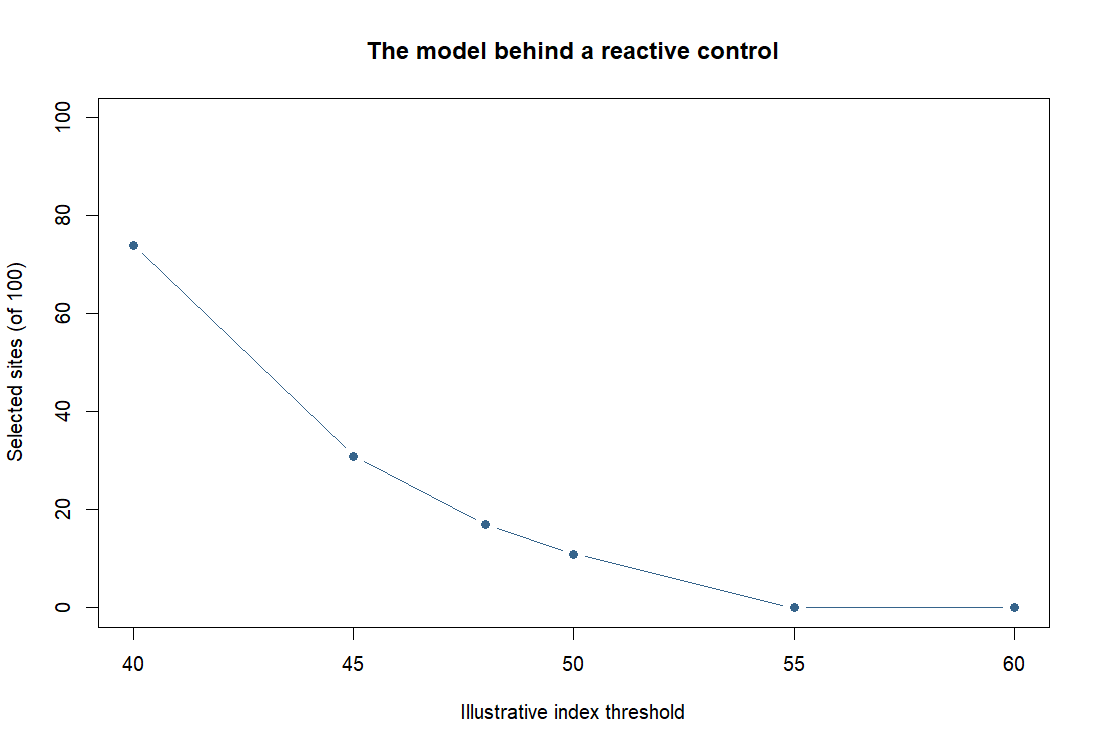

In [2]:
plot(thresholds,counts,type="b",pch=19,col="steelblue4",ylim=c(0,100),
     xlab="Illustrative index threshold",ylab="Selected sites (of 100)",
     main="The model behind a reactive control")

## Follow the dependency graph
`input$seed → field() → selected() → output$map / output$selected`.
`input$threshold` changes which sites are selected, but does not regenerate the field.
`input$palette` changes the map colors, but changes neither the field nor the selection.
`reactive()` caches a value until one of its dependencies changes. `renderPlot()` and
`renderTable()` recalculate their output when the reactive values they use become invalid.

The complete app separates `model.R` (pure computation) from `app.R` (controls, reactive
expressions, plots, and downloads). `tools/test_shiny.R` checks that changing the threshold
preserves the field and that changing the seed changes the values. A separate browser check
is needed to confirm the exported interface responds correctly.

## Run and publish
For desktop R, install `shiny` and run `shiny::runApp("shiny/app")` from the repository root.
For static hosting, install the build dependencies with `Rscript tools/install_shiny.R`, then
run `Rscript tools/export_shiny.R`. The combined site build copies the export into `/shiny/`.
Readers need no local R installation. Initial runtime and package downloads require a connection.

Shiny code in a browser is visible to readers. This example has no credentials, private data,
external service calls, or server-side persistence. The browser's resource limits still apply.
Shinylive has its own runtime/assets version; it need not match the notebook kernel's webR version.

## Practice and check
1. Move the threshold from 48 to 55; the number selected cannot increase.
2. Change only the palette; the summary and CSV numbers should be unchanged.
3. Restore the same seed; confirm the same observations return.
4. Add a control for noise strength. Decide which reactive expression should depend on it.
**Checkpoint:** a control should invalidate exactly the calculations that use it. A new color
is not a new observation. A threshold is not a scientifically justified risk standard.

## Sources and attribution
[Shiny for R, Posit and contributors](https://shiny.posit.co/r/getstarted/);
[Shinylive for R, Schloerke, Chang, Stagg, Aden-Buie and contributors](https://posit-dev.github.io/r-shinylive/);
[Shiny reactive expressions](https://shiny.posit.co/r/reference/shiny/latest/reactive.html).
Shiny and the R Shinylive package are MIT-licensed; their dependencies retain separate licenses.
All app code, lesson prose, and simulated data in this repository are original.